# PHYS 142/242 — Assignment 2: Tunneling in the Double Potential Well

**Name:** Ken Nguyen
**TSN:** 200288141
**My $\alpha$:** $\alpha = 0.3 + 141/5000 = 0.3282$

I did parts A–D and skipped bonus E. Everything runs top to bottom (**Restart → Run All**). I moved A(ii) to the end, because reading the Problem A result properly needs the eigenstates from B and the two-state curve from D.

## Setup

**Conventions.** $m=\hbar=1$. Grid of $N_D+1=601$ points on $[-4,4]$, $\Delta x=8/600$. Time step $\epsilon=\pi/128$. Integrals are $\int f\,dx\approx\Delta x\sum_{i=0}^{N_D}f(x_i)$ over **all** points.

**Potential and harmonic approximation.**
$$
V(x)=\alpha x^4-2x^2+\frac1\alpha,\qquad x_{\min}=\frac1{\sqrt\alpha},\qquad V(\pm x_{\min})=0,\qquad V(0)=\frac1\alpha .
$$
$V''(\pm x_{\min})=12\alpha x_{\min}^2-4=8$ for every $\alpha$, so near each minimum $V_\pm=4(x\mp x_{\min})^2=\tfrac12\omega^2(x\mp x_{\min})^2$ with $\omega=2\sqrt2$, whose ground states are
$$
\psi_\pm(x)=\left(\frac{\omega}{\pi}\right)^{1/4}e^{-\frac{\omega}{2}(x\mp x_{\min})^2},\qquad
\psi_S=\frac{\psi_++\psi_-}{\sqrt2},\quad\psi_A=\frac{\psi_+-\psi_-}{\sqrt2}.
$$

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse.linalg                              # also loads scipy.sparse
from numba import njit

TSN = "200288141"
ALPHA = 0.3 + int(TSN[-3:]) / 5000                     # = 0.3282
BOXSIZE, ND = 8.0, 600                                 # interval [-4, 4], 600 intervals
DELTAX = BOXSIZE / ND
x = np.linspace(-BOXSIZE / 2, BOXSIZE / 2, ND + 1)     # 601 points, both endpoints included
DELTAT = np.pi / 128                                   # time step epsilon
XMIN = 1 / np.sqrt(ALPHA)                              # well minima at +/- XMIN
OMEGA = 2 * np.sqrt(2)                                 # harmonic frequency (V'' = 8 = omega^2)
N_EXPORT = np.arange(0, 2049, 64)                      # results.json steps n = 0, 64, ..., 2048


@njit
def V(x, alpha):
    """Double-well potential, eq. (1). @njit so the compiled kernel builder can call it."""
    return alpha * x**4 - 2 * x**2 + 1 / alpha


def integrate(f):
    """Grid integral: dx * sum over all 601 points (assignment convention)."""
    return DELTAX * np.sum(f)


def normalize(psi):
    return psi / np.sqrt(integrate(np.abs(psi)**2))


def plot_mean(ax, tt, curves, title):
    """<x>(t) panel; curves = [(values, label, plot-style dict), ...]."""
    for y, label, style in curves:
        ax.plot(tt, y, label=label, **style)
    ax.axhline(0, color="gray", lw=0.6)
    ax.set(xlabel=r"$t$", ylabel=r"$\langle x\rangle(t)$", xlim=(0, tt[-1]), title=title)


psi_plus, psi_minus = ((OMEGA / np.pi)**0.25 * np.exp(-OMEGA * (x - c)**2 / 2) for c in (+XMIN, -XMIN))  # eq. (5)
print(f"alpha = {ALPHA}, x_min = {XMIN:.6f}, V(0) = {V(0.0, ALPHA):.6f}, grid norm of psi_+ = {integrate(psi_plus**2):.8f}")

alpha = 0.3282, x_min = 1.745544, V(0) = 3.046923, grid norm of psi_+ = 0.99999996


---
## Problem A: Path-integral tunneling — theory

**Setup.** I start from $\psi(x,0)=\psi_+(x)$ and track $\langle x\rangle(t)=\int x|\psi|^2dx$. The tunneling time $t_\text{tunnel}$ is the first **major** minimum of $\langle x\rangle(t)$.

**Propagator.** $\psi(x_b,t+\epsilon)=\int K(x_b,\epsilon;x_a,0)\,\psi(x_a,t)\,dx_a$ with $K=\langle x_b|e^{-i\hat H\epsilon}|x_a\rangle$. Since $\hat H$ is time-independent, the **same** $K$ advances the state at every step.

**Short-time kernel.** For a short step the dominant path is a straight line, and the midpoint rule gives $\int_0^\epsilon V\,dt\approx\epsilon V(\bar x)$:
$$
S\approx\frac{(x_b-x_a)^2}{2\epsilon}-\epsilon\,V\!\left(\tfrac{x_a+x_b}{2}\right),
\qquad
\tilde K(x_b,\epsilon;x_a,0)=\exp\left[i\left(\frac{(x_b-x_a)^2}{2\epsilon}-V\!\left(\tfrac{x_a+x_b}{2}\right)\epsilon\right)\right].
$$
The full kernel is $A\,e^{iS}$ with $A=\sqrt{1/(2\pi i\epsilon)}$. $A$ is a constant, so dropping it only rescales $\psi$; renormalizing every step, $\psi\leftarrow\psi/\sqrt{\int|\psi|^2dx}$, removes it and also corrects the non-unitarity of the finite grid.

**Matrix form.** On the grid, one step is a matrix–vector product, $\psi_i^\text{new}=\Delta x\sum_j\tilde K_{ij}\psi_j$ (row $i$ = arrival $x_b$, column $j$ = start $x_a$). With $x_i-x_j=(i-j)\Delta x$ and $\tfrac{x_i+x_j}{2}=x_{(i+j)/2}$,
$$
\tilde K_{ij}=p_{|i-j|}\,q_{i+j},\qquad p_k=e^{i\kappa k^2},\quad q_s=e^{-i\epsilon V(x_{s/2})},\quad \kappa=\frac{\Delta x^2}{2\epsilon}\approx3.6\times10^{-3},
$$
$$
\tilde K=
\begin{pmatrix}
q_0 & p_1q_1 & p_2q_2 & \cdots & p_{N_D}q_{N_D}\\
p_1q_1 & q_2 & p_1q_3 & \cdots & p_{N_D-1}q_{N_D+1}\\
p_2q_2 & p_1q_3 & q_4 & \cdots & p_{N_D-2}q_{N_D+2}\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
p_{N_D}q_{N_D} & p_{N_D-1}q_{N_D+1} & p_{N_D-2}q_{N_D+2} & \cdots & q_{2N_D}
\end{pmatrix}.
$$
- **Symmetric** ($\tilde K=\tilde K^T$) but not Hermitian. **Dense**: $|\tilde K_{ij}|=1$, so every point reaches every point in one step.
- The kinetic phase is constant along diagonals (jump length $|i-j|$); the potential phase is constant along anti-diagonals (midpoint), and is the only place $\alpha$ enters. The diagonal is $e^{-i\epsilon V(x_i)}$.
- Only jumps with $|i-j|\lesssim\sqrt{\pi/\kappa}\approx29$ points ($\sqrt{2\pi\epsilon}\approx0.39$) add coherently; longer jumps cancel. For $|i-j|\gtrsim433$ the grid no longer resolves the phase (aliasing).
- $\tilde K$ is built once ($601\times601$) and reused. It is dense although $H$ is tridiagonal because $\tilde K\approx e^{-iH\epsilon}$: exponentiating a local operator couples every point.

**What I expect.** Expanding $\psi_+=\sum_nc_n\phi_n$ in energy eigenstates,
$$
\langle x\rangle(t)=\sum_{m,n}c_mc_n\,x_{mn}\cos\big((E_n-E_m)t\big),\qquad x_{mn}=\int\phi_m\,x\,\phi_n\,dx .
$$
- **Parity:** $x$ is odd, so $x_{mn}\neq0$ only for opposite-parity pairs.
- The $\phi_0$–$\phi_1$ pair gives the **slow** tunneling oscillation with period $2\pi/\Delta E$, so $t_\text{tunnel}\approx\pi/\Delta E$.
- $\psi_+$ is only the *harmonic* ground state, so it also contains higher states, which add **fast** wiggles. These shift the minimum, so I measure $t_\text{tunnel}$ from the curve instead of setting it to $\pi/\Delta E$.
- The barrier $1/\alpha\approx3.05$ is higher than in the lecture example ($\alpha=0.4$: $2.5$), so I expect slower tunneling than the lecture's $t_\text{tunnel}=27.9$.

**Run length.** I need at least $16\pi$ (for `results.json`) and at least one slow period $2\pi/\Delta E\approx132$ (from B). I run to $48\pi\approx151$, which covers one full oscillation but stops before the next left minimum ($3\pi/\Delta E\approx198$), so the deepest point of the run is the first major minimum.

### A(i) Run and plot
I evolve $\psi_+$ through one full slow oscillation and mark the measured $t_\text{tunnel}$ on $\langle x\rangle(t)$.

K~ symmetric: True;  t_tunnel = 63.9609, <x> = -1.7171


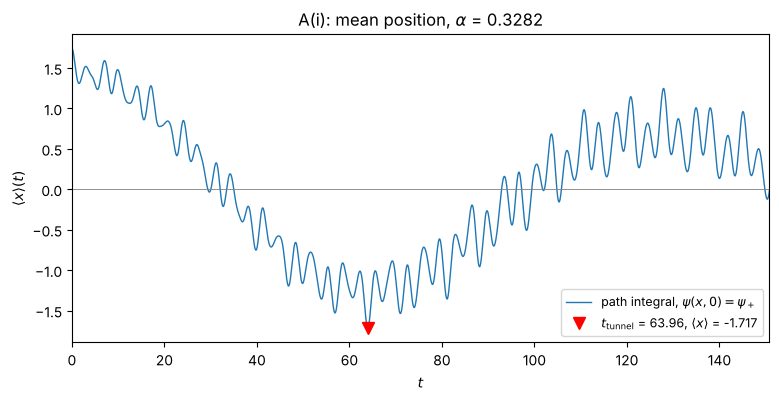

In [2]:
@njit
def build_kernel(x, dt, alpha):
    """K~_ij = exp{ i[ (x_i - x_j)^2 / (2 dt) - V((x_i + x_j)/2) dt ] }; row i = arrival, column j = start."""
    K = np.empty((x.size, x.size), dtype=np.complex128)
    for i in range(x.size):
        for j in range(x.size):
            K[i, j] = np.exp(1j * (0.5 * (x[i] - x[j])**2 / dt - V(0.5 * (x[i] + x[j]), alpha) * dt))
    return K


@njit
def evolve(psi0, K, dx, nt):
    """nt steps of psi <- dx K psi, renormalized every step. Returns prob[n, i] = |psi(x_i, n dt)|^2."""
    psi = psi0.astype(np.complex128) / np.sqrt(dx * np.sum(np.abs(psi0)**2))
    prob = np.empty((nt + 1, psi.size))
    prob[0] = np.abs(psi)**2
    for n in range(nt):
        psi = dx * (K @ psi)                                    # one step: matrix-vector product
        psi = psi / np.sqrt(dx * np.sum(np.abs(psi)**2))        # renormalize (prefactor dropped)
        prob[n + 1] = np.abs(psi)**2
    return prob


K_tilde = build_kernel(x, DELTAT, ALPHA)                        # built once (first call also compiles)
T_RUN = 48 * np.pi                                              # >= 16 pi and >= 2 pi/dE (checked in B)
t = np.arange(int(np.ceil(T_RUN / DELTAT)) + 1) * DELTAT
x_mean_A = DELTAX * (evolve(psi_plus, K_tilde, DELTAX, t.size - 1) @ x)  # <x>(t) = dx sum_i x_i |psi_i|^2
n_tunnel = np.argmin(x_mean_A)                                  # deepest point = first major minimum
t_tunnel = t[n_tunnel]
x_mean_pi = x_mean_A[N_EXPORT]                                  # for results.json
print(f"K~ symmetric: {np.allclose(K_tilde, K_tilde.T)};  t_tunnel = {t_tunnel:.4f}, <x> = {x_mean_A[n_tunnel]:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
plot_mean(ax, t, [(x_mean_A, r"path integral, $\psi(x,0)=\psi_+$", dict(lw=1))],
          rf"A(i): mean position, $\alpha$ = {ALPHA}")
ax.plot(t_tunnel, x_mean_A[n_tunnel], "rv", ms=9,
        label=rf"$t_\mathrm{{tunnel}}$ = {t_tunnel:.2f}, $\langle x\rangle$ = {x_mean_A[n_tunnel]:.3f}")
ax.legend(loc="lower right", fontsize=9)
plt.show()

### A(ii)
I come back to this at the end, after D: interpreting the curve needs B's eigenstates and D's two-state curve as a reference.

---
## Problem B: Numerical eigenstates — theory

**Goal.** I need the two lowest solutions $(E_0,\phi_0)$, $(E_1,\phi_1)$ of $-\tfrac12\phi''+V\phi=E\phi$. They give $\Delta E$ (for A and D), the reference energies for C, and D's initial state.

**Three-point derivative.** Adding the Taylor expansions of $\phi_{i\pm1}$,
$$
\frac{\phi_{i+1}-2\phi_i+\phi_{i-1}}{\Delta x^2}=\phi_i''+\frac{\Delta x^2}{12}\phi_i''''+\dots,
$$
so the method is second order: the error scales as $\Delta x^2$.

**Hamiltonian matrix** ($d_i=\frac1{\Delta x^2}+V(x_i)$, $\tau=\frac1{2\Delta x^2}$; here $1/\Delta x^2=5625$):
$$
H=\begin{pmatrix}
d_0 & -\tau & & & \\
-\tau & d_1 & -\tau & & \\
 & \ddots & \ddots & \ddots & \\
 & & -\tau & d_{N_D-1} & -\tau\\
 & & & -\tau & d_{N_D}
\end{pmatrix}
=\underbrace{\frac{1}{2\Delta x^2}\,\mathrm{tridiag}(-1,2,-1)}_{T}+\mathrm{diag}\big(V(x_i)\big).
$$
**Boundaries.** Row 0 reads $d_0\phi_0-\tau\phi_1=E\phi_0$, i.e. $\phi_{-1}=0$. The matrix therefore puts hard walls ($\phi=0$) one step *outside* the box, at $x_0-\Delta x$ and $x_{N_D}+\Delta x$.

**Properties.**
- **Real symmetric:** the $E_n$ are real and the eigenvectors are orthogonal and real.
- **Sparse:** about 1800 nonzeros out of $601^2\approx361{,}000$.
- **Parity:** the grid-reversal matrix $J$ (ones on the anti-diagonal) satisfies $JHJ=H$, so eigenvectors are even or odd: $\phi_0$ even (no node), $\phi_1$ odd (node at $0$).
- **Positive definite** ($T>0$, $V\ge0$), so every $E_n>0$. The spectrum spans $0<E_n\lesssim2/\Delta x^2+\max V\approx11{,}300$, and the states I need ($\sim1.3$) sit at the very bottom.

**Shift-invert.** $(H-\sigma I)^{-1}\phi_n=\frac1{E_n-\sigma}\phi_n$: the eigenvectors are unchanged, and the eigenvalues nearest $\sigma$ become the largest, which is what ARPACK finds fastest. $\sigma=0$ works because all $E_n>0$. The harmonic estimates $1/E\approx0.7$ (lowest doublet) versus $\approx0.24$ (next doublet) are well separated. The inverse is never formed: a tridiagonal $LU$ factorization makes each solve $\mathcal O(N_D)$.

**Normalization and signs.** The solver returns unit vectors, $\sum_i|v_i|^2=1$, so $\phi_i=v_i/\sqrt{\Delta x}$ gives $\Delta x\sum_i|\phi_i|^2=1$. The sign is arbitrary, so I fix $\phi_0>0$ and the right lobe of $\phi_1>0$; then $(\phi_0+\phi_1)/\sqrt2$ sits in the right well.

**Expected accuracy.**
- **Grid:** the three-point kinetic term underestimates the energy by about $\frac{\Delta x^2}{24}\langle p^4\rangle$. With the harmonic $\langle p^4\rangle_0=3(\omega/2)^2=6$, this gives $\delta E\approx-4\times10^{-5}$: energies slightly **too low**, with 4–5 matching digits.
- **Box:** the walls push $E$ up, but $V(\pm4)\approx55\gg E$, so the effect is negligible.
- **Gap:** $E_0$ and $E_1$ have similar same-sign errors, which largely cancel in $\Delta E$.
- **Convergence tests:** I expect halving $\Delta x$ to divide the error by $4$, and $E_\text{half}+\tfrac13(E_\text{half}-E_\text{orig})$ extrapolates to $\Delta x\to0$; a larger box isolates the wall effect.

### B(i) Validate first
Before trusting the solver at my $\alpha$, I test it at $\alpha=0.4,\,0.6$ ($\lambda=\alpha/4=0.10,\,0.15$) against Table I of Banerjee & Bhatnagar.

In [3]:
def make_hamiltonian(alpha, L=BOXSIZE, nd=ND):
    """Sets the grid (dx = L/nd) and builds the sparse three-point Hamiltonian H."""
    xg = np.linspace(-L / 2, L / 2, nd + 1)
    dx = L / nd                                         # grid spacing
    off = np.full(nd, -1 / (2 * dx**2))                 # H_{i,i+1} = H_{i+1,i} = -1/(2 dx^2)
    H = scipy.sparse.diags([off, 1 / dx**2 + V(xg, alpha), off], [-1, 0, 1], format="csc")  # H_ii = 1/dx^2 + V
    return xg, dx, H


def lowest_two(alpha, L=BOXSIZE, nd=ND):
    """Two lowest eigenpairs by shift-invert (sigma = 0), normalized and sign-fixed."""
    xg, dx, H = make_hamiltonian(alpha, L, nd)
    E, v = scipy.sparse.linalg.eigsh(H, k=2, sigma=0, which="LM")
    order = np.argsort(E)
    E, phi = E[order], v[:, order] / np.sqrt(dx)        # unit vectors -> dx sum |phi|^2 = 1
    phi[:, 0] *= np.sign(np.sum(phi[:, 0]))             # phi0 positive
    phi[:, 1] *= np.sign(np.sum(phi[xg > 0, 1]))        # right lobe of phi1 positive
    return xg, dx, H, E[0], E[1], phi[:, 0], phi[:, 1]


reference = {0.4: (1.2345071627860, 1.3469408689225),  # Banerjee & Bhatnagar, lambda = 0.10
             0.6: (1.0624992479565, 1.4210868905393)}  # lambda = 0.15
print(f"{'alpha':>5} {'n':>2} {'ours (ND=600)':>14} {'reference':>14} {'error':>10} {'error (ND=1200)':>16} {'ratio':>6}")
for a_val, refs in reference.items():
    E_orig, E_half = lowest_two(a_val)[3:5], lowest_two(a_val, nd=2 * ND)[3:5]
    for n in range(2):
        err, err_h = E_orig[n] - refs[n], E_half[n] - refs[n]
        print(f"{a_val:>5} {n:>2} {E_orig[n]:>14.10f} {refs[n]:>14.10f} {err:>10.2e} {err_h:>16.2e} {err / err_h:>6.2f}")

alpha  n  ours (ND=600)      reference      error  error (ND=1200)  ratio
  0.4  0   1.2344772371   1.2345071628  -2.99e-05        -7.48e-06   4.00
  0.4  1   1.3469042749   1.3469408689  -3.66e-05        -9.15e-06   4.00
  0.6  0   1.0624798130   1.0624992480  -1.94e-05        -4.86e-06   4.00
  0.6  1   1.4210435761   1.4210868905  -4.33e-05        -1.08e-05   4.00


**Answer (B(i)):**
- **4–5 digits agree**: 4 for $E_0$ at $\alpha=0.4$, and 5 for the other three energies.
- Every error is **negative** and of size $2$–$4\times10^{-5}$, as predicted by the grid estimate $-\frac{\Delta x^2}{24}\langle p^4\rangle\approx-4\times10^{-5}$.
- Halving $\Delta x$ divides every error by **4.00**. So the agreement is limited by the second-order grid error of the three-point Laplacian, not by the box (B(ii): the box changes energies by only $\sim10^{-9}$) or by the solver.

### B(ii) Convergence at $\alpha=0.3282$
I rerun with half the grid spacing ($N_D=1200$) and with a larger box ($[-6,6]$, $N_D=900$, same $\Delta x$), and compare each with the original grid.

In [4]:
grids = [("Original", BOXSIZE, ND), ("Half spacing", BOXSIZE, 2 * ND), ("Larger box", 12.0, 900)]
rows = {name: (L, nd) + lowest_two(ALPHA, L, nd)[3:5] for name, L, nd in grids}
dE_orig = rows["Original"][3] - rows["Original"][2]
print(f"{'grid':<13} {'interval':>9} {'ND':>5} {'E0':>14} {'E1':>14} {'dE':>14} {'dE - dE_orig':>13}")
for name, (L, nd, e0, e1) in rows.items():
    print(f"{name:<13} {f'[{-L/2:g},{L/2:g}]':>9} {nd:>5} {e0:>14.10f} {e1:>14.10f} {e1 - e0:>14.10f} {e1 - e0 - dE_orig:>13.2e}")

x_B, _, H, E0, E1, phi0, phi1 = lowest_two(ALPHA)       # original grid: used from here on
DELTA_E = E1 - E0
print(f"\ndE = {DELTA_E:.10f}, pi/dE = {np.pi / DELTA_E:.4f};  A's run length OK (2pi/dE < 48 pi < 3pi/dE):",
      2 * np.pi / DELTA_E < T_RUN < 3 * np.pi / DELTA_E)

grid           interval    ND             E0             E1             dE  dE - dE_orig
Original         [-4,4]   600   1.2924391655   1.3401570118   0.0477178463      0.00e+00
Half spacing     [-4,4]  1200   1.2924650092   1.3401842693   0.0477192601      1.41e-06
Larger box       [-6,6]   900   1.2924391629   1.3401570089   0.0477178460     -3.63e-10

dE = 0.0477178463, pi/dE = 65.8368;  A's run length OK (2pi/dE < 48 pi < 3pi/dE): True


**Answer (B(ii)):**
- **Original grid:** $E_0=1.2924391655$, $E_1=1.3401570118$, $\Delta E=0.0477178463$.
- **Half spacing:** $\Delta E$ changes by $+1.4\times10^{-6}$, while $E_0,E_1$ each shift by $\approx+2.6\times10^{-5}$. The grid error dominates, and it largely cancels in the gap (same-sign errors). Richardson extrapolation gives $\Delta E\approx0.047720$.
- **Larger box:** changes of only $\sim10^{-9}$ ($\Delta E$: $-3.6\times10^{-10}$). The walls are irrelevant because $V(\pm4)\approx55$.
- **Quoted digits** (stable across the grids): $E_0=1.2924$, $E_1=1.3402$, $\Delta E=0.04772$.
- **Code that sets the grid and updates $H$:** `make_hamiltonian(alpha, L, nd)` sets `dx = L / nd` and rebuilds the diagonals of $H$; `lowest_two` calls it, so each grid is a single function call.

### B(iii) Eigenfunctions

norms: 1.000000000000, 1.000000000000;  overlap <phi0|phi1> = -2.8e-16


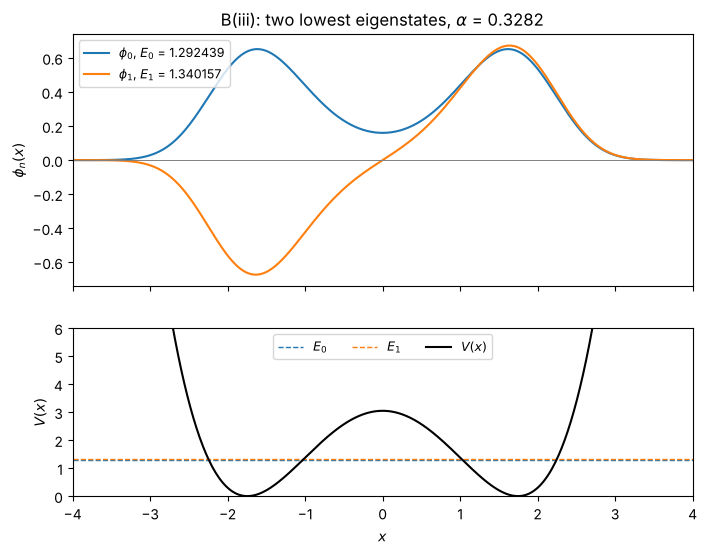

In [5]:
print(f"norms: {integrate(phi0**2):.12f}, {integrate(phi1**2):.12f};  overlap <phi0|phi1> = {integrate(phi0 * phi1):.1e}")
fig, (ax_phi, ax_V) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for n, (phi, E) in enumerate([(phi0, E0), (phi1, E1)]):
    ax_phi.plot(x, phi, label=rf"$\phi_{n}$, $E_{n}$ = {E:.6f}")
    ax_V.axhline(E, color=f"C{n}", ls="--", lw=1, label=rf"$E_{n}$")
ax_phi.axhline(0, color="gray", lw=0.7)
ax_phi.set(ylabel=r"$\phi_n(x)$", title=rf"B(iii): two lowest eigenstates, $\alpha$ = {ALPHA}")
ax_phi.legend(loc="upper left", fontsize=9)
ax_V.plot(x, V(x, ALPHA), color="black", label=r"$V(x)$")
ax_V.set(xlabel=r"$x$", ylabel=r"$V(x)$", xlim=(x[0], x[-1]), ylim=(0, 6))
ax_V.legend(loc="upper center", fontsize=9, ncol=3)
plt.show()

**Answer (B(iii)):** both states are normalized ($\Delta x\sum|\phi_n|^2=1$) and orthogonal. $\phi_0$ is even and nodeless; $\phi_1$ is odd, with its node at the barrier centre. Both have nearly identical lobes in each well, i.e. they are the symmetric and antisymmetric combinations of a single-well state. That is why $E_0$ and $E_1$ (nearly overlapping lines, gap $0.048$) are almost degenerate.

---
## Problem C: Harmonic-approximation energies — theory

**Trial states.** $\psi_S$ (even) and $\psi_A$ (odd), built from the local Gaussians but evaluated with the **full** $\hat H$ (B's matrix).

**Variational principle.** For any trial function,
$$
E[\psi]=\frac{\int\psi^*\hat H\psi\,dx}{\int|\psi|^2dx}=\frac{\sum_n|c_n|^2E_n}{\sum_n|c_n|^2}\ \ge\ \text{lowest }E_n\text{ contained in }\psi .
$$
So $E_S\ge E_0$, and $E_A\ge E_1$ (the odd $\psi_A$ has no even components): **both signed errors are $\ge0$**. The energy error is second order in the wave-function error.

**Why keep the denominators.** $\psi_\pm$ overlap:
$$
S=\int\psi_+\psi_-\,dx=e^{-\omega x_{\min}^2}=e^{-\omega/\alpha}\approx1.8\times10^{-4},\qquad
\int|\psi_S|^2=1+S,\quad\int|\psi_A|^2=1-S .
$$
Dropping the denominators would shift $E_S,E_A$ by $\sim E\,S\approx2\times10^{-4}$: ten times B's grid error and about $5\%$ of the harmonic gap. On the grid, $E_S=\boldsymbol\psi_S^TH\boldsymbol\psi_S/\boldsymbol\psi_S^T\boldsymbol\psi_S$, and likewise for $E_A$.

**Two-state (Rayleigh–Ritz) structure.** In the basis $\{\psi_+,\psi_-\}$, with $h_d=\langle\psi_\pm|\hat H|\psi_\pm\rangle$ and $h_o=\langle\psi_+|\hat H|\psi_-\rangle$:
$$
\mathsf H=\begin{pmatrix}h_d&h_o\\h_o&h_d\end{pmatrix},\quad
\mathsf S=\begin{pmatrix}1&S\\S&1\end{pmatrix}
\;\Rightarrow\;
E_S=\frac{h_d+h_o}{1+S},\quad E_A=\frac{h_d-h_o}{1-S},\quad
\Delta E_\text{harm}=\frac{2(Sh_d-h_o)}{1-S^2}.
$$
The gap depends only on $S$ and $h_o$, i.e. on the **barrier region** where $\psi_+$ and $\psi_-$ overlap.

**Analytic values.** The exact expansion $V=4u^2+4\sqrt\alpha\,u^3+\alpha u^4$ ($u=x-x_{\min}$), together with $\hat H\psi_\pm=\frac\omega2\psi_\pm+(V-V_\pm)\psi_\pm$ and Gaussian moments ($\sigma^2=\frac1{2\omega}$), gives
$$
h_d=\sqrt2+\frac{3\alpha}{32},\qquad
h_o=S\Big[\frac\omega2-\frac3\alpha-\frac3\omega+\frac{3\alpha}{32}\Big],\qquad
\boxed{\Delta E_\text{harm}=\frac{6S}{1-S^2}\Big(\frac1\alpha+\frac1\omega\Big)}.
$$

**Why the gap is much worse than the energies.**
1. $\Delta E_\text{harm}-\Delta E=\delta_A-\delta_S$ (with $\delta_S=E_S-E_0$, $\delta_A=E_A-E_1$) is divided by the small $\Delta E$, whereas the energy errors are divided by $E\approx1.3$.
2. The gap is set by the amplitude at the barrier centre:
$$
\Delta E=\frac{\phi_0(0)\,\phi_1'(0)}{2\int_0^\infty\phi_0\phi_1\,dx}\approx\phi_0(0)\,\phi_1'(0).
$$
3. The parabola overestimates the barrier: $V_+(0)=4/\alpha\approx12.2$ versus $V(0)=1/\alpha\approx3.05$. The Gaussian therefore decays too fast and leaves too little amplitude at $x=0$, which makes the gap far too small.
4. The energies are dominated by the wells, where the harmonic fit is good, and their error is only second order.

### C(i) Harmonic energies vs. exact energies

In [6]:
psi_S = (psi_plus + psi_minus) / np.sqrt(2)             # unnormalized, as defined
psi_A = (psi_plus - psi_minus) / np.sqrt(2)
E_S, E_A = (integrate(p * (H @ p)) / integrate(p * p) for p in (psi_S, psi_A))   # Rayleigh quotients, B's H
print(f"{'':<8} {'harmonic':>11} {'exact (B)':>11} {'signed err':>11} {'rel. err':>9}")
for name, approx, exact in [("E_S, E0", E_S, E0), ("E_A, E1", E_A, E1), ("gap", E_A - E_S, DELTA_E)]:
    print(f"{name:<8} {approx:>11.8f} {exact:>11.8f} {approx - exact:>11.4f} {abs(approx - exact) / exact:>9.2%}")

S = integrate(psi_plus * psi_minus)
print(f"\nS = {S:.6e} (analytic {np.exp(-OMEGA / ALPHA):.6e});  gap {E_A - E_S:.6e} "
      f"(analytic 6S(1/alpha + 1/omega)/(1-S^2) = {6 * S * (1 / ALPHA + 1 / OMEGA) / (1 - S**2):.6e})")

            harmonic   exact (B)  signed err  rel. err
E_S, E0   1.44311023  1.29243917      0.1507    11.66%
E_A, E1   1.44680056  1.34015701      0.1066     7.96%
gap       0.00369033  0.04771785     -0.0440    92.27%

S = 1.808218e-04 (analytic 1.808218e-04);  gap 3.690325e-03 (analytic 6S(1/alpha + 1/omega)/(1-S^2) = 3.689281e-03)


**Answer (C(i)):**
- Both signed errors are **positive**, as the variational principle requires: $\delta_S=E_S-E_0=+0.151$ ($11.7\%$) and $\delta_A=E_A-E_1=+0.107$ ($8.0\%$).
- **Gap error:** $(E_A-E_S)-\Delta E=\delta_A-\delta_S=-0.044$. $E_S$ overshoots more than $E_A$, so the harmonic gap $0.0037$ is about $13\times$ too small ($92\%$ error).
- **The energies are more accurate** in relative terms ($8$–$12\%$) than the gap ($92\%$): the two errors are similar, but their difference is divided by $\Delta E\approx0.048$ instead of $E\approx1.3$.
- The grid values match the analytic results ($S=e^{-\omega/\alpha}$ and the boxed $\Delta E_\text{harm}$) to $\sim10^{-6}$.

### C(ii) Harmonic vs. exact ground state

at x = 0: phi0/psi_S = 8.64;  barrier |x| < 1.027;  V(0) = 3.05 vs V_+(0) = 12.19


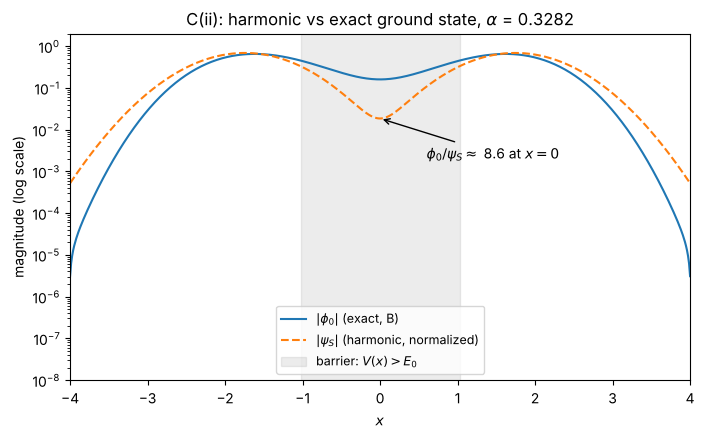

In [7]:
psi_S_n = normalize(psi_S)
i0 = np.argmin(np.abs(x))                                          # x = 0
x_turn = np.abs(x[(np.abs(x) < XMIN) & (V(x, ALPHA) > E0)]).max()  # inner turning point (barrier edge)
ratio = phi0[i0] / psi_S_n[i0]
print(f"at x = 0: phi0/psi_S = {ratio:.2f};  barrier |x| < {x_turn:.3f};  V(0) = {V(0.0, ALPHA):.2f} vs V_+(0) = {4 * XMIN**2:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(x, np.abs(phi0), label=r"$|\phi_0|$ (exact, B)")
ax.semilogy(x, np.abs(psi_S_n), "--", label=r"$|\psi_S|$ (harmonic, normalized)")
ax.axvspan(-x_turn, x_turn, color="gray", alpha=0.15, label=r"barrier: $V(x) > E_0$")
ax.annotate(rf"$\phi_0/\psi_S \approx$ {ratio:.1f} at $x=0$", xy=(0, psi_S_n[i0]), xytext=(0.6, 2e-3),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.set(xlabel=r"$x$", ylabel="magnitude (log scale)", xlim=(x[0], x[-1]), ylim=(1e-8, 2),
       title=rf"C(ii): harmonic vs exact ground state, $\alpha$ = {ALPHA}")
ax.legend(loc="lower center", fontsize=9)
plt.show()

**Answer (C(ii)):**
- **Discrepancy (marked):** $|\psi_S|\approx|\phi_0|$ in the wells, but inside the barrier ($|x|<1.03$) $|\psi_S|$ is far too small: $\phi_0(0)/\psi_S(0)\approx8.6$.
- **Limits of the harmonic approximation:** $V_\pm$ fits only near the minima. Toward the centre the true barrier is much lower than the parabola ($V(0)=3.05$ vs $V_+(0)=12.2$), so the Gaussian decays too fast. In the outer walls the true $V$ is steeper, and there $|\phi_0|<|\psi_S|$.
- **Why the gap fails while the energies do not:** the energies come mainly from the wells and are off by $8$–$12\%$ ($\delta_S=0.151$, $\delta_A=0.107$). The gap is set by the barrier amplitude ($\Delta E\approx\phi_0(0)\phi_1'(0)$), exactly where $\psi_S$ is $\sim9\times$ too small. Its error, $\delta_A-\delta_S=-0.044$, is comparable to $\Delta E=0.048$ itself; since $E/\Delta E\approx27$, $\sim10\%$ energy errors become a $92\%$ gap error.

---
## Problem D: Comparing two evolution methods — theory

**Initial state.** $\psi(x,0)=(\phi_0+\phi_1)/\sqrt2$ with B's signs, so the two add on the right and cancel on the left: the state is in the right well. Orthonormality gives $\int|\psi(x,0)|^2=\tfrac12(1+1+2\int\phi_0\phi_1)=1$. I evolve both to the first step at or after $T=2\pi/\Delta E$.

**D(i) derivation.** Each eigenstate only acquires a phase:
$$
\psi(x,t)=\tfrac1{\sqrt2}\left(e^{-iE_0t}\phi_0+e^{-iE_1t}\phi_1\right)
\;\Rightarrow\;
|\psi|^2=\tfrac12\left[\phi_0^2+\phi_1^2+2\phi_0\phi_1\cos(\Delta E\,t)\right]
$$
($\phi_n$ real, since $H$ is real symmetric). Then
$$
\langle x\rangle(t)=\tfrac12\left[x_{00}+x_{11}+2x_{01}\cos(\Delta E\,t)\right],\qquad x_{mn}=\int\phi_m\,x\,\phi_n\,dx .
$$
- **Normalization** enters through the $1/\sqrt2$, which gives the $\tfrac12$, and through orthonormality, which keeps $\int|\psi|^2=1$ at all $t$ (the cross term integrates to zero).
- **Symmetry** enters through parity: $\phi_0^2$ and $\phi_1^2$ are even and $x$ is odd, so $x_{00}=x_{11}=0$; $\phi_0\phi_1$ is odd, so $x\phi_0\phi_1$ is even and $x_{01}\neq0$. Hence
$$
\boxed{\langle x\rangle(t)=x_{01}\cos(\Delta E\,t/\hbar),\qquad t_\text{tunnel}=\pi\hbar/\Delta E}
$$
- The first minimum is where $\cos=-1$. At that time $|\psi|^2=\tfrac12(\phi_0-\phi_1)^2(x)=|\psi(-x,0)|^2$: the mirror image, in the left well. On the symmetric grid all of this holds exactly, because B's eigenvectors are exactly even or odd.

**D(ii).** Same path-integral code as A. Since the initial state contains only $\phi_0$ and $\phi_1$, an exact propagator would reproduce D(i) exactly, with no wiggles. **Any difference is numerical error.**

**D(iii): what I expect.** $\Delta x\,\tilde K$ is only approximately $e^{-iH\epsilon}$, so the path integral effectively has slightly different eigenstates and energies:

| Pattern | Mechanism |
|---|---|
| growing phase drift, shifted zero crossings | $\Delta E_\text{PI}\neq\Delta E$: $\cos((\Delta E+\delta)t)-\cos(\Delta Et)\approx-\delta\,t\sin(\Delta Et)$ |
| fast wiggles on the PI curve only | the two-state state leaks into higher PI eigenstates, beating at higher-state gaps |
| shrinking amplitude or offset | $\tilde K$ is not unitary; renormalization reweights the components |

The errors accumulate step by step, so I expect the discrepancy to be largest late in the run.

**Which parameter controls the error.** $\Delta x$ contributes only $\sim10^{-5}$ (B). The time step does more: $\tilde K$ is time-symmetric, so its error is **second order in $\epsilon$**. But **$\epsilon$ cannot be reduced alone**: the kinetic phase $\kappa k^2$ aliases at $k^*=\pi/\kappa$ ("ghost paths"), and the method needs $k^*>N_D$, i.e. $2\pi\epsilon>L\Delta x$ (now $0.154>0.107$). Halving only $\epsilon$ violates this. A valid check halves $\epsilon$ **and** $\Delta x$ together.

### D(i)–(ii) Eigenstate and path-integral evolution

In [8]:
psi0_D = (phi0 + phi1) / np.sqrt(2)                     # right-well two-state initial state
T_D = 2 * np.pi / DELTA_E                               # one full oscillation
t_D = np.arange(int(np.ceil(T_D / DELTAT)) + 1) * DELTAT   # up to the first step at or after T
t_tunnel_D = np.pi / DELTA_E

# D(i): eigenstate evolution (exact at any t, no time stepping)
x01 = integrate(phi0 * x * phi1)
x_mean_eig_D = x01 * np.cos(DELTA_E * t_D)              # every step, for the comparison
x_mean_eig = x01 * np.cos(DELTA_E * N_EXPORT * DELTAT)  # 33 export times, for results.json

# D(ii): path integral, same code as A
prob_PI_D = evolve(psi0_D, K_tilde, DELTAX, t_D.size - 1)
x_mean_PI_D = DELTAX * (prob_PI_D @ x)
print(f"x01 = {x01:.6f};  T = {T_D:.4f} ({t_D.size - 1} steps);  t_tunnel = pi/dE = {t_tunnel_D:.4f};  "
      f"PI minimum at t = {t_D[np.argmin(x_mean_PI_D)]:.4f}")

x01 = 1.550021;  T = 131.6737 (5365 steps);  t_tunnel = pi/dE = 65.8368;  PI minimum at t = 66.2925


### D(iii) Comparison

max |diff| = 7.5377e-02 at t = 128.7071: <x>_PI = 1.459140, <x>_eig = 1.534517


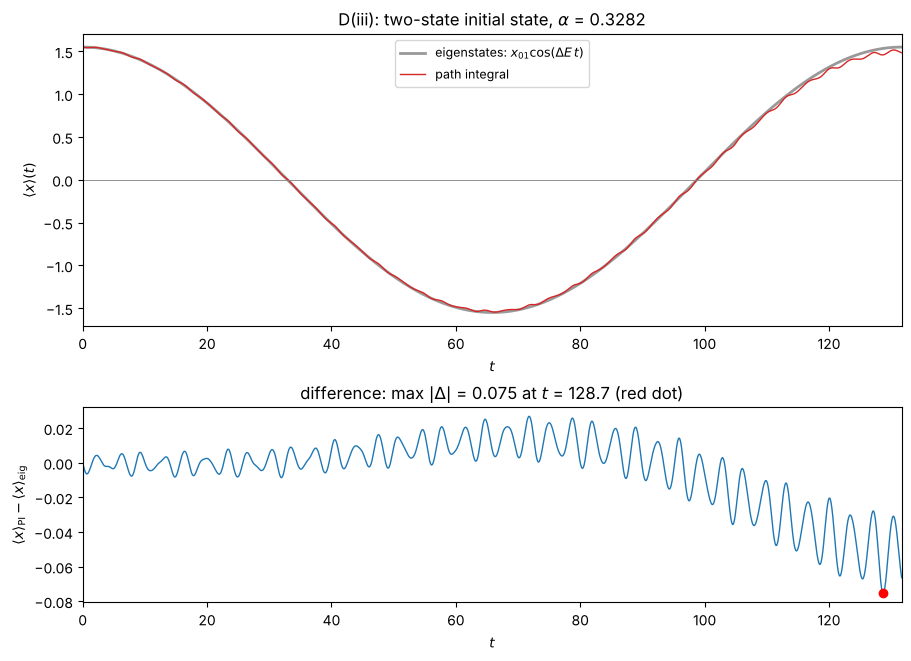

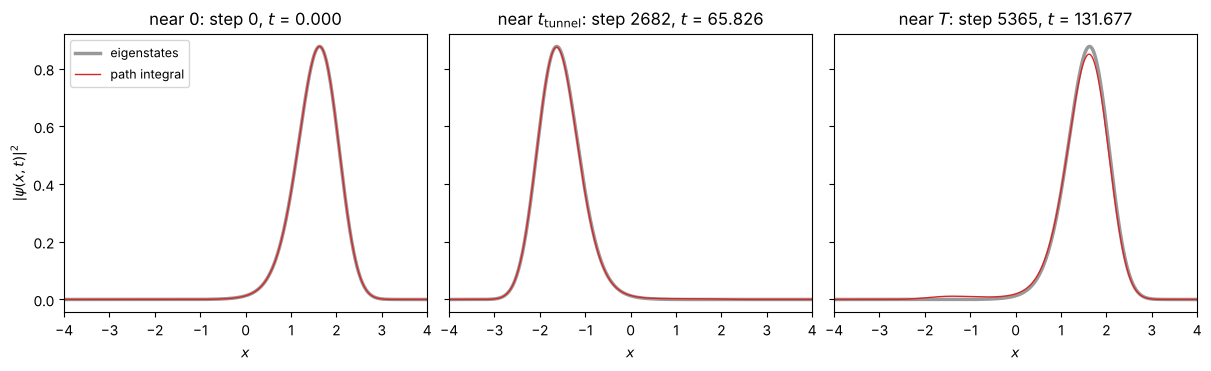

In [9]:
diff = x_mean_PI_D - x_mean_eig_D
n_max = np.argmax(np.abs(diff[t_D <= T_D]))             # eq. (12): only steps with n eps <= T
print(f"max |diff| = {abs(diff[n_max]):.4e} at t = {t_D[n_max]:.4f}: <x>_PI = {x_mean_PI_D[n_max]:.6f}, <x>_eig = {x_mean_eig_D[n_max]:.6f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), gridspec_kw={"height_ratios": [3, 2]}, constrained_layout=True)
plot_mean(ax1, t_D, [(x_mean_eig_D, r"eigenstates: $x_{01}\cos(\Delta E\,t)$", dict(lw=2, color="0.6")),
                     (x_mean_PI_D, "path integral", dict(lw=1, color="C3"))],
          rf"D(iii): two-state initial state, $\alpha$ = {ALPHA}")
ax1.legend(loc="upper center", fontsize=9)
ax2.plot(t_D, diff, lw=1)
ax2.plot(t_D[n_max], diff[n_max], "ro")                 # maximum discrepancy
ax2.set(xlabel=r"$t$", xlim=(0, t_D[-1]), ylabel=r"$\langle x\rangle_\mathrm{PI}-\langle x\rangle_\mathrm{eig}$",
        title=rf"difference: max $|\Delta|$ = {abs(diff[n_max]):.3f} at $t$ = {t_D[n_max]:.1f} (red dot)")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, constrained_layout=True)
for ax, (name, tt) in zip(axes, [("0", 0.0), (r"t_\mathrm{tunnel}", t_tunnel_D), ("T", T_D)]):
    n = np.argmin(np.abs(t_D - tt))                     # nearest time step
    psi_eig = (np.exp(-1j * E0 * t_D[n]) * phi0 + np.exp(-1j * E1 * t_D[n]) * phi1) / np.sqrt(2)   # eq. (11)
    ax.plot(x, np.abs(psi_eig)**2, lw=2.5, color="0.6", label="eigenstates")
    ax.plot(x, prob_PI_D[n], lw=1, color="C3", label="path integral")
    ax.set(title=rf"near ${name}$: step {n}, $t$ = {t_D[n]:.3f}", xlabel=r"$x$", xlim=(x[0], x[-1]))
axes[0].set_ylabel(r"$|\psi(x,t)|^2$")
axes[0].legend(fontsize=9)
plt.show()

**Answer (D(iii)):**
- **Max discrepancy:** $0.075$ at $t=128.71$ (near $T=131.67$), where $\langle x\rangle_\text{PI}=1.459$ and $\langle x\rangle_\text{eig}=1.535$.
- **Pattern:** zero at $t=0$ and growing with time. It consists of fast wiggles (period $\approx3.5$) that appear only on the PI curve, plus a slow drift that turns negative late in the run. The PI minimum is slightly late ($66.29$ vs $65.84$), and at $T$ the PI peak is lower, with a small remnant left in the left well. The eigenstate curve is a pure cosine, so all of this is numerical.
- **Likely cause:** the finite time step. The PI propagator has slightly different eigenstates and energies than B's $H$, so the two-state state leaks into higher states (the wiggles, at a higher-state gap $\approx E_2-E_1$) and the slow oscillation drifts. The errors accumulate, so the discrepancy peaks near $T$.
- **Targeted check:** I would halve $\epsilon$ **and** $\Delta x$ together ($\epsilon=\pi/256$, $N_D=1200$; halving $\epsilon$ alone would violate $2\pi\epsilon>L\Delta x$). If the time step is the cause, the error is second order in $\epsilon$, so I predict the max discrepancy will drop by about $4\times$, to $\approx0.019$.

---
## A(ii) Back to Problem A: reading the result

weight of psi_+ in phi0 + phi1 = 0.9472;  fast period ~ 3.41 (slow: 131.7)


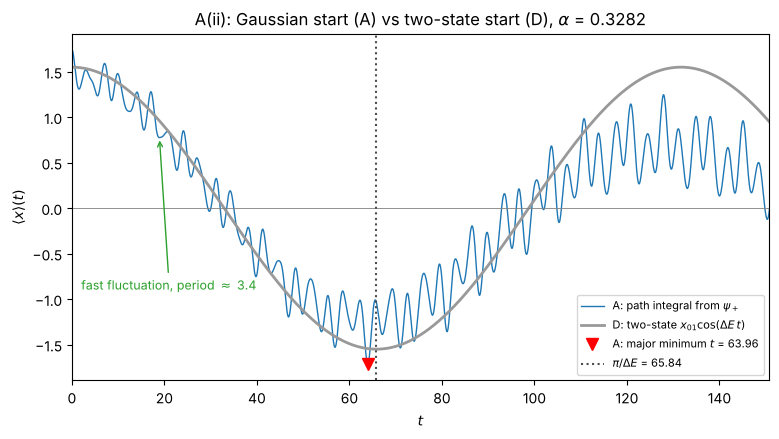

In [10]:
two_state = sum(integrate(phi * normalize(psi_plus))**2 for phi in (phi0, phi1))   # |c0|^2 + |c1|^2
mins = np.flatnonzero((x_mean_A[1:-1] < x_mean_A[:-2]) & (x_mean_A[1:-1] < x_mean_A[2:])) + 1  # local minima
P_fast = np.median(np.diff(t[mins]))                    # typical spacing = fast-fluctuation period
print(f"weight of psi_+ in phi0 + phi1 = {two_state:.4f};  fast period ~ {P_fast:.2f} (slow: {2 * np.pi / DELTA_E:.1f})")

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_mean(ax, t, [(x_mean_A, r"A: path integral from $\psi_+$", dict(lw=1)),
                  (x01 * np.cos(DELTA_E * t), r"D: two-state $x_{01}\cos(\Delta E\,t)$", dict(lw=2, color="0.6"))],
          rf"A(ii): Gaussian start (A) vs two-state start (D), $\alpha$ = {ALPHA}")
ax.plot(t_tunnel, x_mean_A[n_tunnel], "rv", ms=9, label=rf"A: major minimum $t$ = {t_tunnel:.2f}")
ax.axvline(np.pi / DELTA_E, color="0.3", ls=":", label=rf"$\pi/\Delta E$ = {np.pi / DELTA_E:.2f}")
ax.annotate(rf"fast fluctuation, period $\approx$ {P_fast:.1f}", xy=(t[mins[5]], x_mean_A[mins[5]]),
            xytext=(2, -0.9), arrowprops=dict(arrowstyle="->", color="C2"), color="C2", fontsize=9)
ax.legend(loc="lower right", fontsize=8)
plt.show()

**Answer (A(ii)):**
- **Major minimum:** $t_\text{tunnel}=63.96$, $\langle x\rangle=-1.717$, compared with $\pi/\Delta E=65.84$ and $-x_{01}=-1.550$ for the two-state curve.
- **Fast fluctuation (marked):** period $\approx3.4$, about $40\times$ faster than the slow transfer (period $2\pi/\Delta E\approx132$). The slow part is $\phi_0$–$\phi_1$ tunneling; the wiggles are beats with higher states.
- **Comparison with D:** D is a single sinusoid. A's minimum is earlier and deeper, it carries large wiggles, and it does not return fully, because only $94.7\%$ of $\psi_+$ is in $\phi_0,\phi_1$ and $5.3\%$ is in higher states.
- **Supporting feature:** A's wiggles are large ($\sim0.3$) **from $t=0$**. D, run with the **same** path-integral code, deviates from a sinusoid by at most $0.075$, growing slowly from zero. So A's departures come from the higher states in its initial state, not from numerical error. The minimum sits where a fast wiggle's low point coincides with the slow minimum, which shifts it away from $\pi/\Delta E$.

---
## Autograded results

In [11]:
results = dict(tsn=TSN, alpha=ALPHA, x_mean_pi=x_mean_pi.tolist(), t_tunnel=float(t_tunnel),
               E0=float(E0), E1=float(E1), phi0=phi0.tolist(), phi1=phi1.tolist(),
               E_S=float(E_S), E_A=float(E_A), x_mean_eig=x_mean_eig.tolist())
with open("results.json", "w") as f:
    json.dump(results, f)

---
## AI use appendix
- **Tool:** Claude Code (Anthropic). Conversation: https://claude.ai/code/session_0139N3Dg8mdWHerwgwr5Vsk8
- **Purpose:** setting up the Python environment and notebook; drafting the theory sections and derivations; writing and debugging the code for A–D; drafting the written answers, which I checked against my own outputs.
- **Prompts:** asked for the theory of each problem first (derivations and matrix forms), then the code for each part, then brief answers; finally asked for the notebook to be condensed.
- **What it got wrong and how I caught it:**
  - It first gave Linux/macOS venv commands (`.venv/bin/python`), which failed in Windows PowerShell; the error message showed the path was wrong, and the fix was `.venv\Scripts\python.exe`.
  - It quoted $x_{\min}=1.745564$; my notebook printed $1.745544$, which is the correct $1/\sqrt{0.3282}$.
  - Its theory estimated the fast-wiggle period in A as $2\pi/\omega\approx2.2$ (harmonic level spacing); the measured period is $\approx3.4$, because the real spacing to the next doublet is smaller than $\omega$. Caught by measuring the period from the spectrum of $\langle x\rangle(t)$.
  - Its C theory predicted that $|\psi_S|$ and $|\phi_0|$ would agree in the outer walls; the log plot shows $|\phi_0|<|\psi_S|$ there (the true wall is steeper than the parabola).